# Drug Toxicity Prediction — Tox21 Dataset
**Track A | Pharmacology + AI Hackathon**

**Pipeline:** Molecular Descriptors + Morgan Fingerprints → XGBoost + Random Forest → SHAP Analysis

In [1]:
# Packages already installed in drug_tox_env
print('All packages ready!')

All packages ready!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, roc_auc_score, confusion_matrix,
    roc_curve, average_precision_score, precision_recall_curve
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
import xgboost as xgb

from rdkit import Chem
from rdkit.Chem import Descriptors, AllChem, rdFingerprintGenerator, Draw
from IPython.display import display

plt.style.use('seaborn-v0_8')
sns.set_palette('husl')
print('All libraries loaded successfully!')

All libraries loaded successfully!


In [3]:
import os
# List files in current directory
for f in os.listdir('.'):
    print(f)


auc_heatmap.png
chemical_space.png
class_distribution.png
collections
descriptor_distributions.png
download_dataset.py
drug-toxicity-prediction.ipynb
drug_tox_env
final_check.py
fix_fstrings.py
fix_notebook.py
fix_syntax_comprehensive.py
generate_dataset.py
patch_shap_cell.py
property_vs_toxicity.png
README.md
requirements.txt
roc_curves.png
run_notebook.py
shap_dependence.png
shap_importance.png
shap_summary.png
tox21.csv


## 1. Load Dataset

In [4]:
# Load from Kaggle or local path — update path as needed
# If running on Kaggle: /kaggle/input/tox21-dataset/tox21.csv
# If local: './tox21.csv'

DATA_PATH = './tox21.csv'  # Updated to local path

df = pd.read_csv(DATA_PATH)

print(f'Dataset Shape: {df.shape}')
print(f'Columns: {list(df.columns)}')
display(df.head())

Dataset Shape: (7831, 14)
Columns: ['mol_id', 'smiles', 'NR-AR', 'NR-AR-LBD', 'NR-AhR', 'NR-Aromatase', 'NR-ER', 'NR-ER-LBD', 'NR-PPAR-gamma', 'SR-ARE', 'SR-ATAD5', 'SR-HSE', 'SR-MMP', 'SR-p53']


,mol_id,smiles,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53
0,TOX00000,CC(=O)Oc1ccccc1C(=O)O,0.0,NaN,1.0,1.0,0.0,0.0,0.0,NaN,0.0,NaN,1.0,0.0
1,TOX00001,Cn1cnc2c1c(=O)n(C)c(=O)n2C,NaN,NaN,0.0,0.0,1.0,0.0,0.0,NaN,0.0,0.0,0.0,NaN
2,TOX00002,C1=CC=CC=C1,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,TOX00003,c1ccc2ccccc2c1,0.0,0.0,0.0,0.0,0.0,NaN,1.0,1.0,NaN,1.0,NaN,1.0
4,TOX00004,ClC(Cl)(Cl)Cl,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0


## 2. Exploratory Data Analysis (EDA)

In [5]:
# Identify target columns (all except mol_id and smiles)
target_cols = [c for c in df.columns if c not in ['mol_id', 'smiles']]
print(f'Found {len(target_cols)} toxicity targets:')
for t in target_cols:
    print(f'  {t}')

Found 12 toxicity targets:
  NR-AR
  NR-AR-LBD
  NR-AhR
  NR-Aromatase
  NR-ER
  NR-ER-LBD
  NR-PPAR-gamma
  SR-ARE
  SR-ATAD5
  SR-HSE
  SR-MMP
  SR-p53


In [6]:
# Missing data analysis
missing_pct = df[target_cols].isnull().mean() * 100
positive_rate = df[target_cols].mean() * 100

summary = pd.DataFrame({
    'Missing_%': missing_pct.round(1),
    'Positive_Rate_%': positive_rate.round(1),
    'Total_Labeled': df[target_cols].notna().sum(),
    'Positives': (df[target_cols] == 1).sum()
})
print('Target Summary:')
display(summary.sort_values('Missing_%'))

Target Summary:


,Missing_%,Positive_Rate_%,Total_Labeled,Positives
NR-AR,19.6,7.3,6300,463
NR-Aromatase,19.6,9.4,6294,593
SR-HSE,19.6,11.2,6296,703
SR-ARE,19.8,22.5,6281,1416
NR-PPAR-gamma,20.1,7.2,6256,452
NR-ER,20.1,15.0,6260,939
SR-MMP,20.3,16.0,6240,1000
NR-AhR,20.3,12.2,6239,762
SR-p53,20.5,9.3,6225,581
NR-ER-LBD,20.5,9.8,6223,611


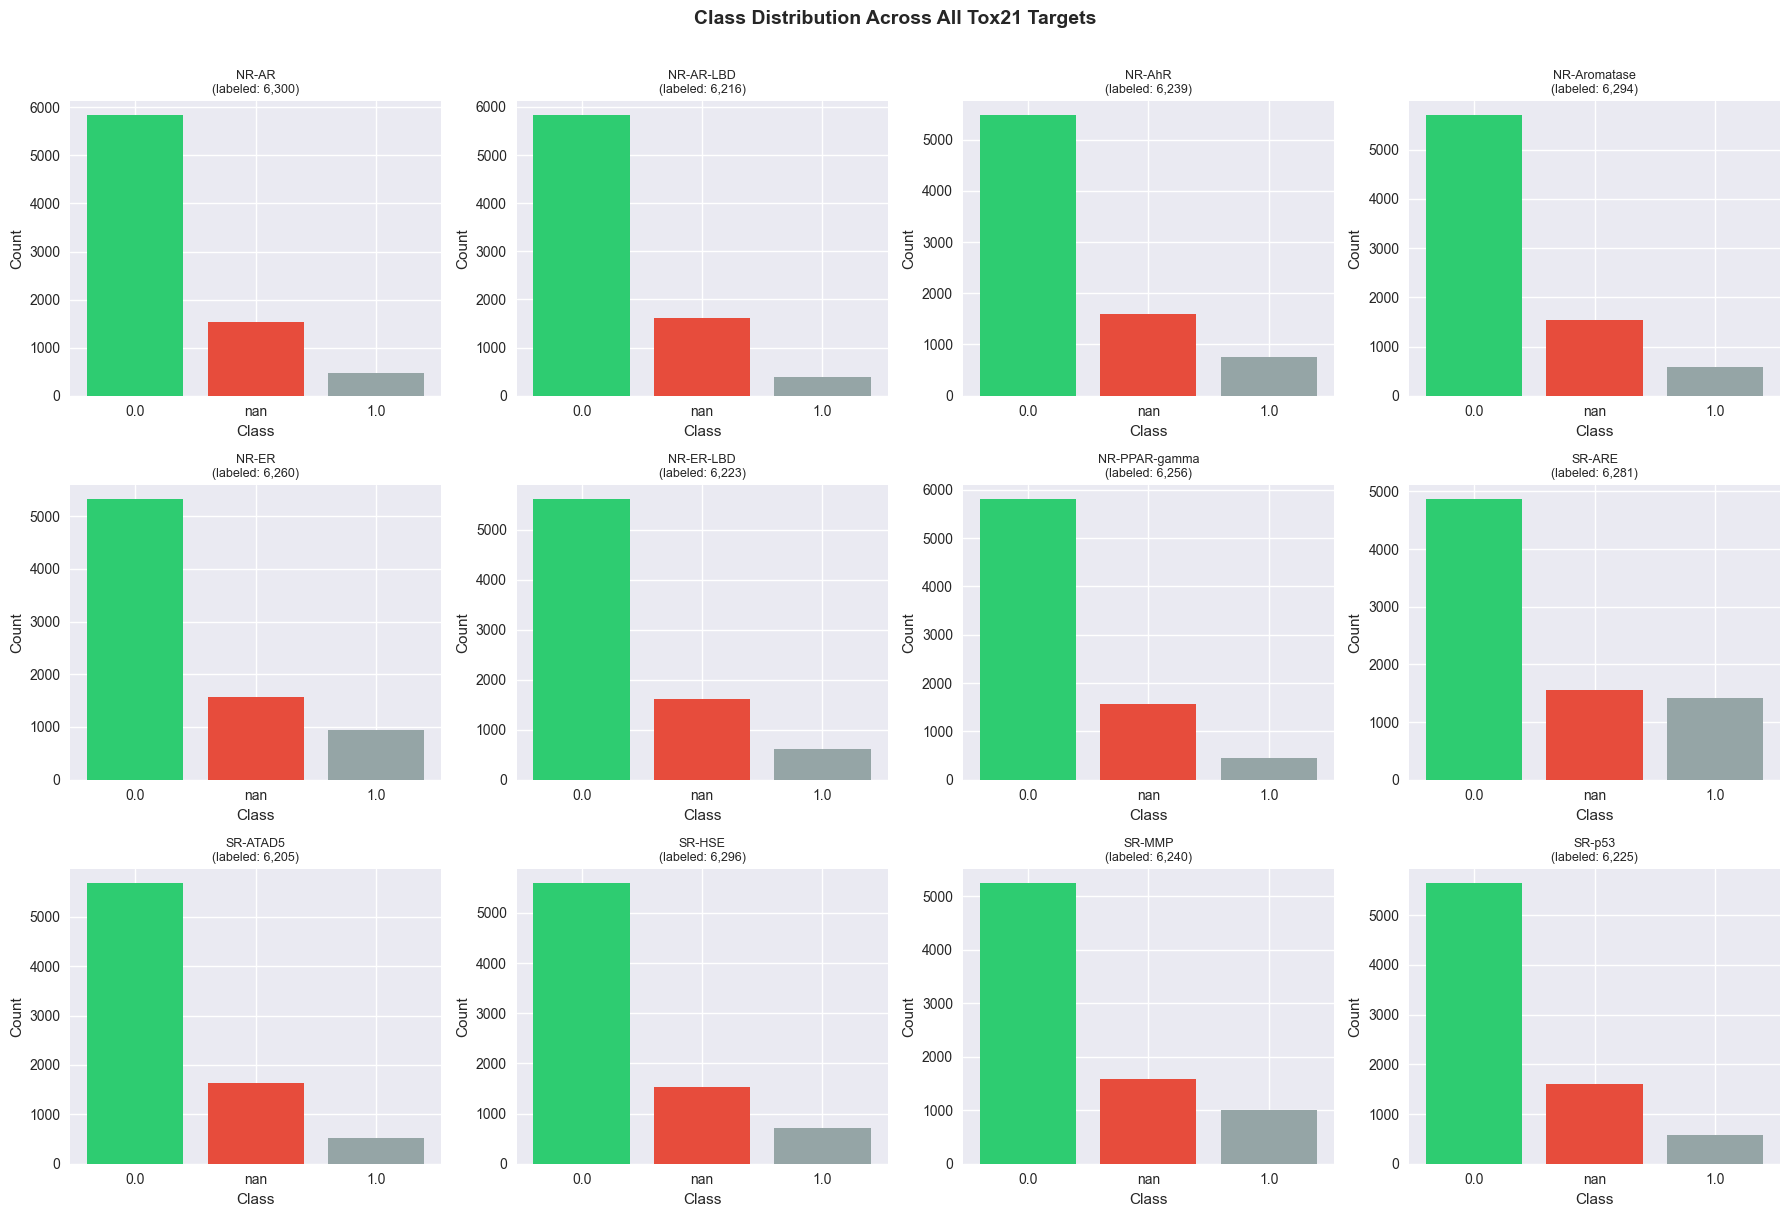

Note: Most targets are heavily imbalanced (toxic compounds are rare)


In [7]:
# Visualize class imbalance across all targets
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(target_cols):
    if i < len(axes):
        counts = df[col].value_counts(dropna=False)
        labels = [f'{v}' for v in counts.index]
        axes[i].bar(labels, counts.values, color=['#2ecc71', '#e74c3c', '#95a5a6'])
        axes[i].set_title(f'{col}\n(labeled: {df[col].notna().sum():,})', fontsize=9)
        axes[i].set_xlabel('Class')
        axes[i].set_ylabel('Count')

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Class Distribution Across All Tox21 Targets', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Note: Most targets are heavily imbalanced (toxic compounds are rare)')

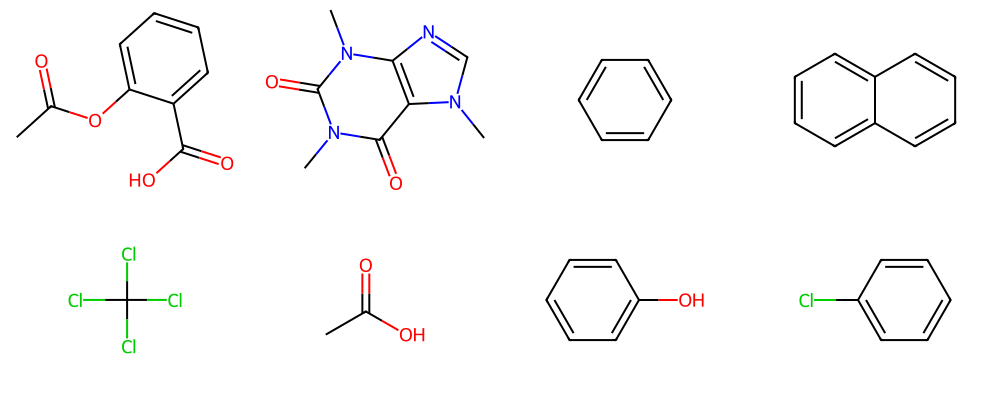

In [8]:
# Visualize first 8 molecules
valid_smiles = df['smiles'].dropna().head(8).tolist()
mol_objs = [Chem.MolFromSmiles(s) for s in valid_smiles]
mol_objs = [m for m in mol_objs if m is not None]
img = Draw.MolsToGridImage(mol_objs[:8], molsPerRow=4, subImgSize=(250, 200))
display(img)

## 3. Feature Engineering

We extract two types of features:
- **Molecular Descriptors**: physicochemical properties (MW, LogP, TPSA, etc.)
- **Morgan Fingerprints**: circular fingerprints encoding local chemical environments (2048 bits, radius=2)

In [9]:
def compute_descriptors(smiles):
    """Compute 12 key molecular descriptors from SMILES string."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return [np.nan] * 12
    return [
        Descriptors.MolWt(mol),              # Molecular weight
        Descriptors.MolLogP(mol),            # Lipophilicity
        Descriptors.NumHDonors(mol),         # H-bond donors
        Descriptors.NumHAcceptors(mol),      # H-bond acceptors
        Descriptors.NumRotatableBonds(mol),  # Flexibility
        Descriptors.NumAromaticRings(mol),   # Aromaticity
        Descriptors.TPSA(mol),              # Topological polar surface area
        mol.GetNumAtoms(),                   # Atom count
        Descriptors.FractionCSP3(mol),       # Fraction sp3 carbons
        Descriptors.NumHeteroatoms(mol),     # Heteroatom count
        Descriptors.RingCount(mol),          # Ring count
        Descriptors.MolMR(mol),              # Molar refractivity
    ]

DESCRIPTOR_NAMES = [
    'MolWt', 'LogP', 'HBD', 'HBA', 'RotBonds', 'AromaticRings',
    'TPSA', 'NumAtoms', 'FracCSP3', 'HeteroAtoms', 'RingCount', 'MolMR'
]

print('Computing molecular descriptors...')
desc_matrix = np.array(df['smiles'].apply(compute_descriptors).tolist())
df_desc = pd.DataFrame(desc_matrix, columns=DESCRIPTOR_NAMES)
print(f'Descriptor matrix shape: {df_desc.shape}')
display(df_desc.describe().round(2))

Computing molecular descriptors...


[21:17:51] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:17:51] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:17:51] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:17:51] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:17:51] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:17:51] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9


[21:17:52] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12


[21:17:52] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12


[21:17:52] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:17:52] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9


...

[21:18:01] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:18:01] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:18:01] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:18:01] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:18:01] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:18:01] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9


[21:18:02] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:18:02] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:18:02] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:18:02] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:18:02] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:18:02] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9


Descriptor matrix shape: (7831, 12)


[21:18:02] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:18:02] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12


,MolWt,LogP,HBD,HBA,RotBonds,AromaticRings,TPSA,NumAtoms,FracCSP3,HeteroAtoms,RingCount,MolMR
count,7717.00,7717.00,7717.00,7717.00,7717.00,7717.00,7717.00,7717.00,7717.00,7717.00,7717.00,7717.00
mean,123.35,1.44,0.71,1.23,0.77,0.83,26.44,8.39,0.36,1.83,0.96,34.23
std,41.34,1.19,0.80,1.00,1.12,0.77,23.25,3.06,0.41,1.35,0.79,12.36
min,41.05,-1.67,0.00,0.00,0.00,0.00,0.00,3.00,0.00,0.00,0.00,11.29
25%,93.13,0.64,0.00,1.00,0.00,0.00,9.23,6.00,0.00,1.00,0.00,26.14
50%,122.13,1.46,1.00,1.00,0.00,1.00,24.06,8.00,0.14,2.00,1.00,33.10
75%,148.16,2.20,1.00,2.00,1.00,1.00,37.30,10.00,0.80,2.00,1.00,40.70
max,290.45,4.58,4.00,6.00,6.00,4.00,132.13,21.00,1.00,7.00,4.00,83.65


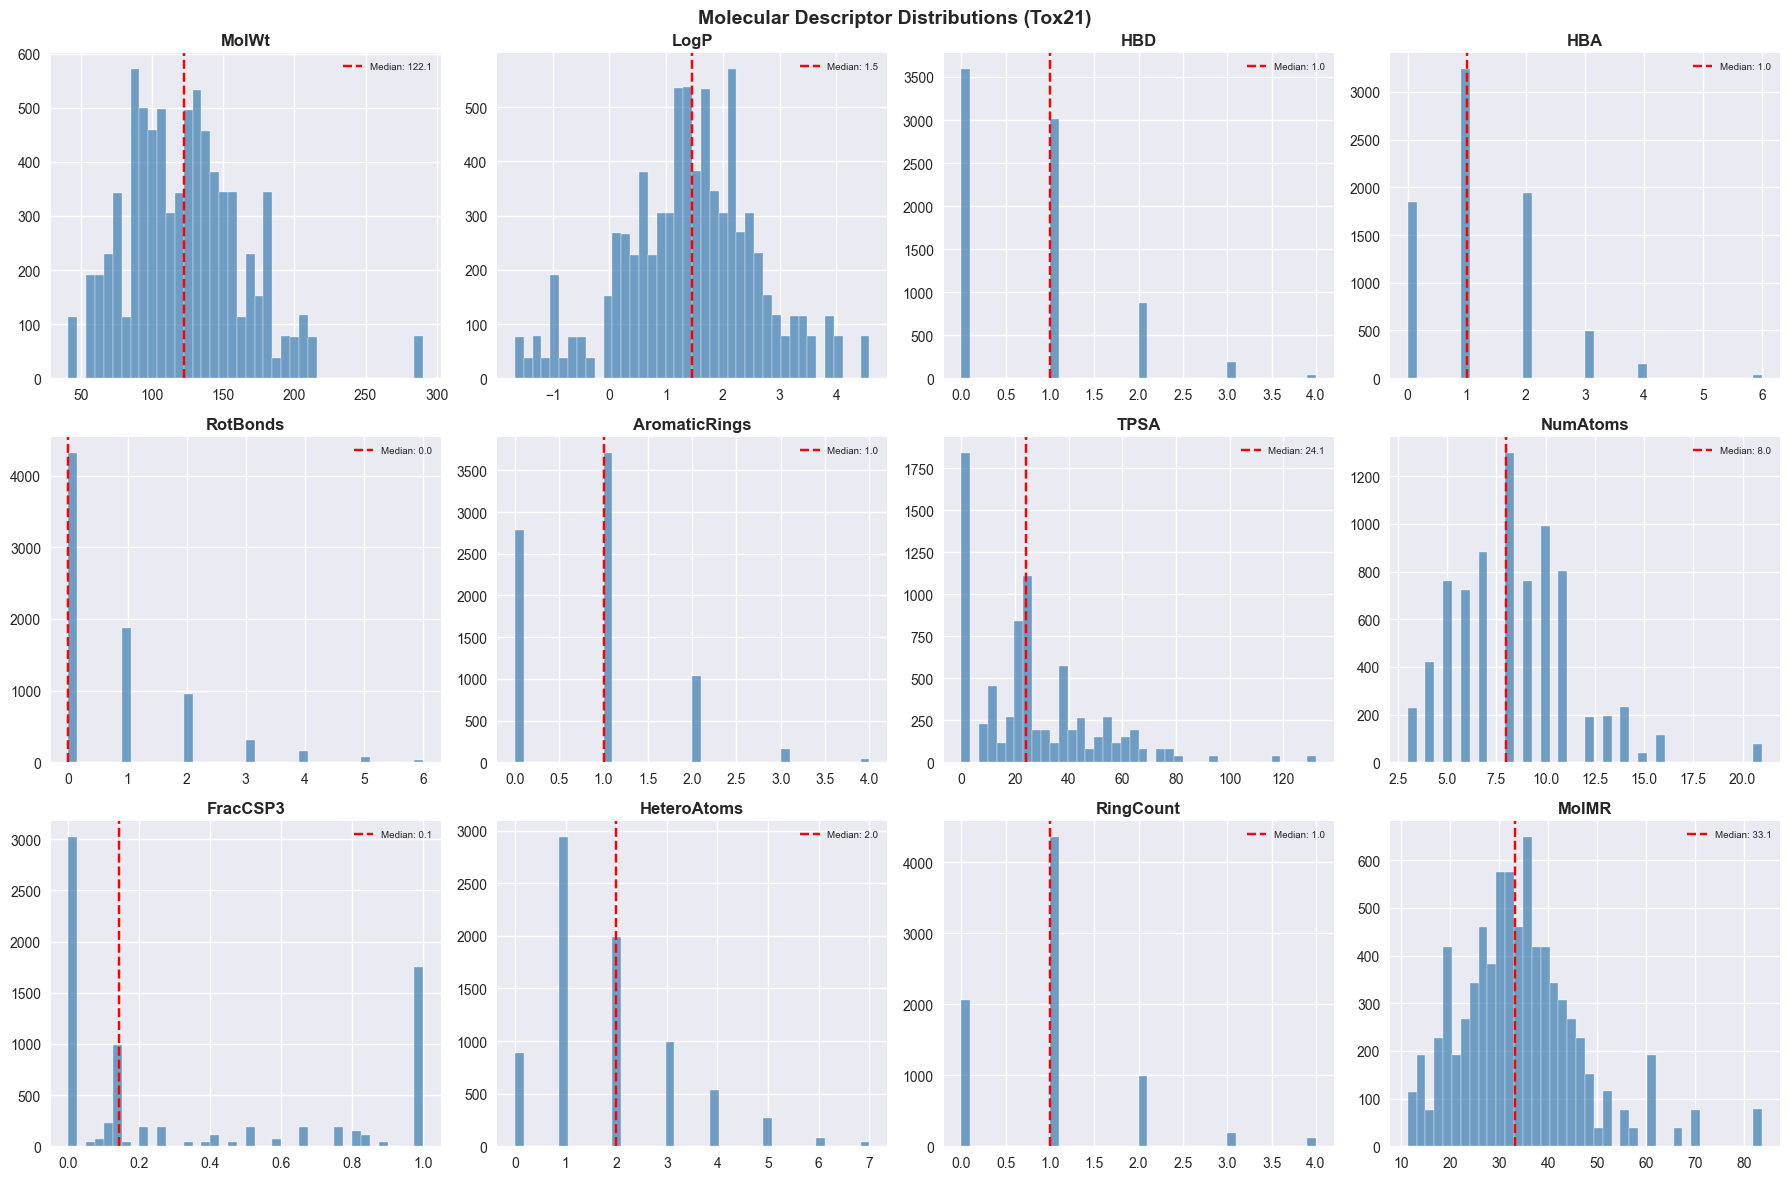

In [10]:
# Plot descriptor distributions
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, desc in enumerate(DESCRIPTOR_NAMES):
    data = df_desc[desc].dropna()
    axes[i].hist(data, bins=40, alpha=0.75, color='steelblue', edgecolor='white')
    axes[i].axvline(data.median(), color='red', linestyle='--', label=f'Median: {data.median():.1f}')
    axes[i].set_title(desc, fontweight='bold')
    axes[i].legend(fontsize=7)

plt.suptitle('Molecular Descriptor Distributions (Tox21)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('descriptor_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# Generate Morgan Fingerprints (2048 bits, radius=2)
print('Generating Morgan fingerprints (radius=2, 2048 bits)...')
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def get_fingerprint(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return [0] * 2048
    return list(morgan_gen.GetFingerprint(mol))

X_fps = np.array(df['smiles'].apply(get_fingerprint).tolist())
print(f'Fingerprint matrix shape: {X_fps.shape}')
print(f'Sparsity (fraction zero bits): {(X_fps == 0).mean():.3f}')

Generating Morgan fingerprints (radius=2, 2048 bits)...


[21:18:11] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:18:11] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:18:11] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:18:11] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:18:12] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:18:12] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12


[21:18:12] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:18:12] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:18:12] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:18:12] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:18:12] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:18:12] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12


[21:18:12] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:18:12] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:18:12] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:18:12] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:18:12] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:18:12] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12


[21:18:12] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:18:12] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:18:12] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:18:12] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:18:13] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:18:13] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12


...

[21:18:26] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:18:26] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:18:26] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:18:26] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:18:26] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:18:26] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9


[21:18:26] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:18:26] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12


[21:18:27] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:18:27] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7 8 9
[21:18:27] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9
[21:18:27] Can't kekulize mol.  Unkekulized atoms: 1 2 3 4 5 6 7 8 9


[21:18:27] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12
[21:18:27] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4 5 6 7 8 9 10 11 12


Fingerprint matrix shape: (7831, 2048)
Sparsity (fraction zero bits): 0.993


In [12]:
# Combine descriptors + fingerprints
X_desc = df_desc.fillna(0).values
X_combined = np.hstack([X_desc, X_fps])
FEATURE_NAMES = DESCRIPTOR_NAMES + [f'FP_{i}' for i in range(2048)]

print(f'Combined feature matrix: {X_combined.shape}')
print(f'  - Molecular descriptors: {X_desc.shape[1]}')
print(f'  - Morgan fingerprint bits: {X_fps.shape[1]}')

Combined feature matrix: (7831, 2060)
  - Molecular descriptors: 12
  - Morgan fingerprint bits: 2048


## 4. Model Training & Evaluation

We train 3 models per toxicity target:
- **XGBoost** (primary — best for imbalanced tabular data)
- **Random Forest** (ensemble baseline)
- **Logistic Regression** (linear baseline)

We use **SMOTE** to handle class imbalance and evaluate using **ROC-AUC** and **PR-AUC**.

In [13]:
# Select viable targets (≥50 positive samples)
MIN_POSITIVE = 50
viable_targets = []

for target in target_cols:
    pos = (df[target] == 1).sum()
    total = df[target].notna().sum()
    if pos >= MIN_POSITIVE and total >= 200:
        viable_targets.append({'target': target, 'positives': pos,
                               'total': total, 'pos_rate': pos/total})

viable_df = pd.DataFrame(viable_targets).sort_values('pos_rate', ascending=False)
print(f'Viable targets for modeling: {len(viable_df)}')
display(viable_df)

Viable targets for modeling: 12


,target,positives,total,pos_rate
7,SR-ARE,1416,6281,0.225442
10,SR-MMP,1000,6240,0.160256
4,NR-ER,939,6260,0.150000
2,NR-AhR,762,6239,0.122135
9,SR-HSE,703,6296,0.111658
5,NR-ER-LBD,611,6223,0.098184
3,NR-Aromatase,593,6294,0.094217
11,SR-p53,581,6225,0.093333
8,SR-ATAD5,522,6205,0.084126
0,NR-AR,463,6300,0.073492


In [14]:
def train_and_evaluate(X_train, X_test, y_train, y_test, target_name):
    """Train XGBoost, Random Forest, Logistic Regression and return results."""
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc = scaler.transform(X_test)

    # Apply SMOTE to training set only
    smote = SMOTE(random_state=42, k_neighbors=min(5, (y_train==1).sum()-1))
    try:
        X_res, y_res = smote.fit_resample(X_train_sc, y_train)
    except Exception:
        X_res, y_res = X_train_sc, y_train  # fallback if SMOTE fails

    scale_pos = max(1, (y_train == 0).sum() / max(1, (y_train == 1).sum()))
    
    models = {
        'XGBoost': xgb.XGBClassifier(
            n_estimators=200, max_depth=5, learning_rate=0.05,
            scale_pos_weight=scale_pos, use_label_encoder=False,
            eval_metric='logloss', random_state=42, n_jobs=-1, verbosity=0
        ),
        'RandomForest': RandomForestClassifier(
            n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1
        ),
        'LogisticRegression': LogisticRegression(
            class_weight='balanced', max_iter=1000, random_state=42
        )
    }

    results = {}
    for name, model in models.items():
        model.fit(X_res, y_res)
        y_prob = model.predict_proba(X_test_sc)[:, 1]
        roc_auc = roc_auc_score(y_test, y_prob)
        pr_auc = average_precision_score(y_test, y_prob)
        results[name] = {
            'model': model, 'scaler': scaler,
            'y_prob': y_prob, 'roc_auc': roc_auc, 'pr_auc': pr_auc
        }
        print(f'  {name:20s} | ROC-AUC: {roc_auc:.4f} | PR-AUC: {pr_auc:.4f}')

    return results

In [15]:
# Train on top 5 targets (or all viable)
TOP_N = 5
top_targets = viable_df.head(TOP_N)['target'].tolist()

all_results = {}
trained_models = {}  # Store best models for SHAP
X_test_store = {}    # Store test sets for SHAP

for target in top_targets:
    print(f"\n{'='*55}")
    print(f'  TARGET: {target}')
    print('='*55)

    mask = df[target].notna()
    X_t = X_combined[mask]
    y_t = df.loc[mask, target].values

    X_train, X_test, y_train, y_test = train_test_split(
        X_t, y_t, test_size=0.2, random_state=42, stratify=y_t
    )
    print(f'  Train: {len(y_train)} | Test: {len(y_test)} | '
          f'Pos rate: {y_train.mean():.2%}')

    results = train_and_evaluate(X_train, X_test, y_train, y_test, target)
    all_results[target] = {'results': results, 'y_test': y_test}

    # Store best model (XGBoost) for SHAP
    scaler = results['XGBoost']['scaler']
    trained_models[target] = results['XGBoost']['model']
    X_test_store[target] = scaler.transform(X_test)

print('\nTraining complete!')


  TARGET: SR-ARE


  Train: 5024 | Test: 1257 | Pos rate: 22.55%


  XGBoost              | ROC-AUC: 0.4696 | PR-AUC: 0.2116


  RandomForest         | ROC-AUC: 0.4777 | PR-AUC: 0.2159


  LogisticRegression   | ROC-AUC: 0.4666 | PR-AUC: 0.2103

  TARGET: SR-MMP


...

  LogisticRegression   | ROC-AUC: 0.5163 | PR-AUC: 0.1309

  TARGET: SR-HSE


  Train: 5036 | Test: 1260 | Pos rate: 11.16%


  XGBoost              | ROC-AUC: 0.5048 | PR-AUC: 0.1121


  RandomForest         | ROC-AUC: 0.5070 | PR-AUC: 0.1148


  LogisticRegression   | ROC-AUC: 0.5107 | PR-AUC: 0.1146

Training complete!


## 5. Results Summary & Visualization

In [16]:
# Build summary dataframe
rows = []
for target, data in all_results.items():
    for model_name, res in data['results'].items():
        rows.append({
            'Target': target,
            'Model': model_name,
            'ROC_AUC': res['roc_auc'],
            'PR_AUC': res['pr_auc']
        })

summary_df = pd.DataFrame(rows)
pivot = summary_df.pivot_table(index='Target', columns='Model', values='ROC_AUC')
print('ROC-AUC by Target and Model:')
display(pivot.round(4))

best_per_target = summary_df.loc[summary_df.groupby('Target')['ROC_AUC'].idxmax()]
print(f'\nAverage Best ROC-AUC: {best_per_target["ROC_AUC"].mean():.4f}')

ROC-AUC by Target and Model:

Model,LogisticRegression,RandomForest,XGBoost
Target,,,
NR-AhR,0.5163,0.5390,0.5225
NR-ER,0.4800,0.4824,0.4827
SR-ARE,0.4666,0.4777,0.4696
SR-HSE,0.5107,0.5070,0.5048
SR-MMP,0.5134,0.5088,0.5066



Average Best ROC-AUC: 0.5047


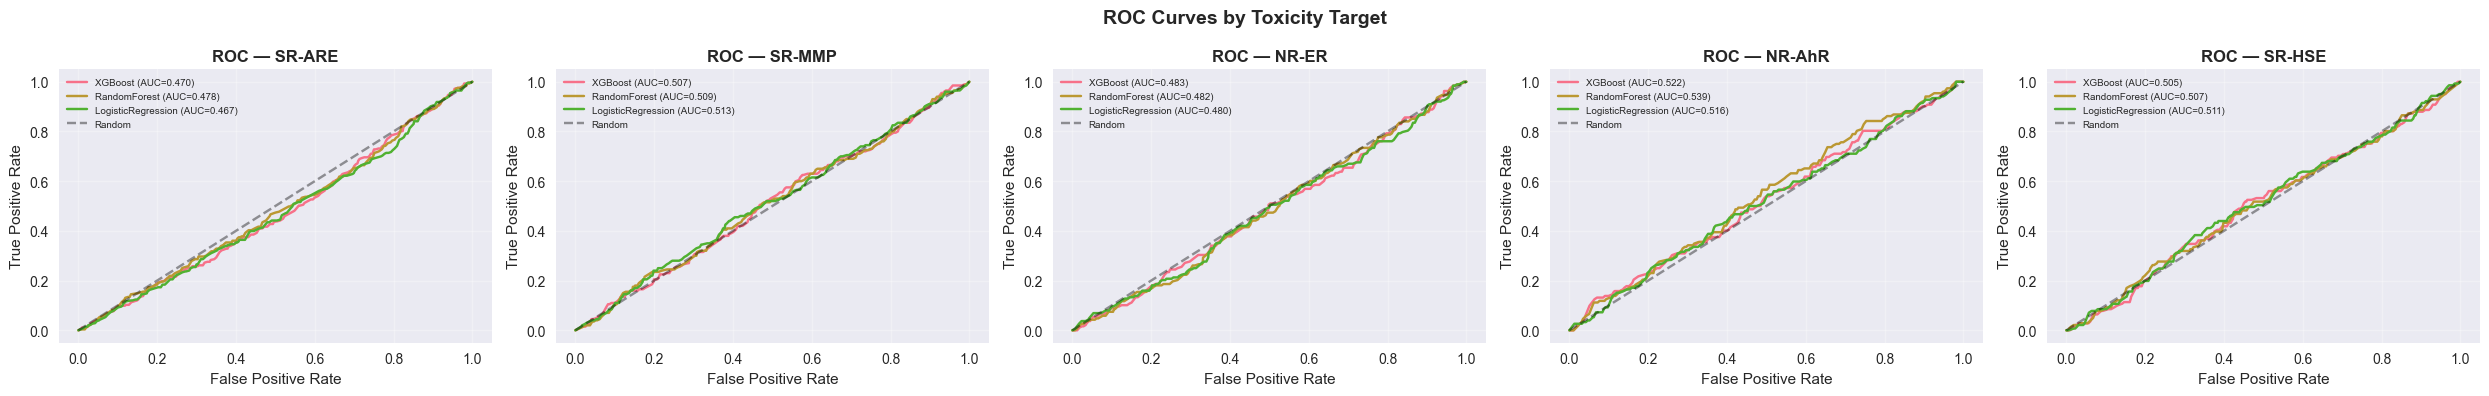

In [17]:
# ROC Curves for all targets (XGBoost only)
fig, axes = plt.subplots(1, len(top_targets), figsize=(5*len(top_targets), 4))
if len(top_targets) == 1:
    axes = [axes]

for ax, target in zip(axes, top_targets):
    y_test = all_results[target]['y_test']
    for model_name, res in all_results[target]['results'].items():
        fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
        ax.plot(fpr, tpr, label=f"{model_name} (AUC={res['roc_auc']:.3f})")
    ax.plot([0,1],[0,1],'k--', alpha=0.4, label='Random')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'ROC — {target}', fontweight='bold')
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

plt.suptitle('ROC Curves by Toxicity Target', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

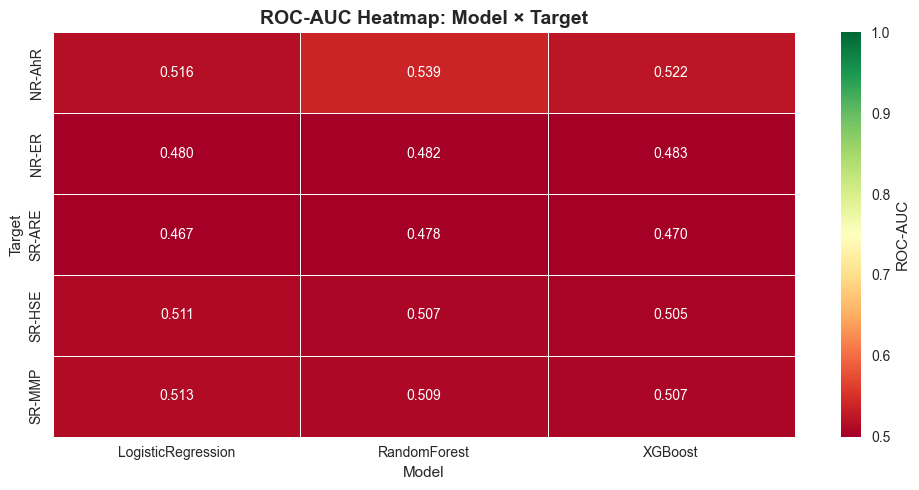

In [18]:
# Heatmap: AUC across models and targets
plt.figure(figsize=(10, 5))
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='RdYlGn',
            vmin=0.5, vmax=1.0, linewidths=0.5, cbar_kws={'label': 'ROC-AUC'})
plt.title('ROC-AUC Heatmap: Model × Target', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('auc_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. SHAP Feature Importance Analysis

SHAP (SHapley Additive exPlanations) tells us **which molecular properties most strongly drive toxicity predictions** for each target.

In [19]:
# SHAP analysis for the primary target (highest-data target)
primary_target = viable_df.iloc[0]['target']
print(f'Running SHAP analysis for primary target: {primary_target}')

model_xgb = trained_models[primary_target]
X_test_sc = X_test_store[primary_target]

# Use a subsample for speed
n_shap = min(500, len(X_test_sc))
X_shap = X_test_sc[:n_shap]

explainer = shap.TreeExplainer(model_xgb)
shap_values = explainer.shap_values(X_shap)

print(f'SHAP values computed for {n_shap} test samples')

Running SHAP analysis for primary target: SR-ARE


SHAP values computed for 500 test samples


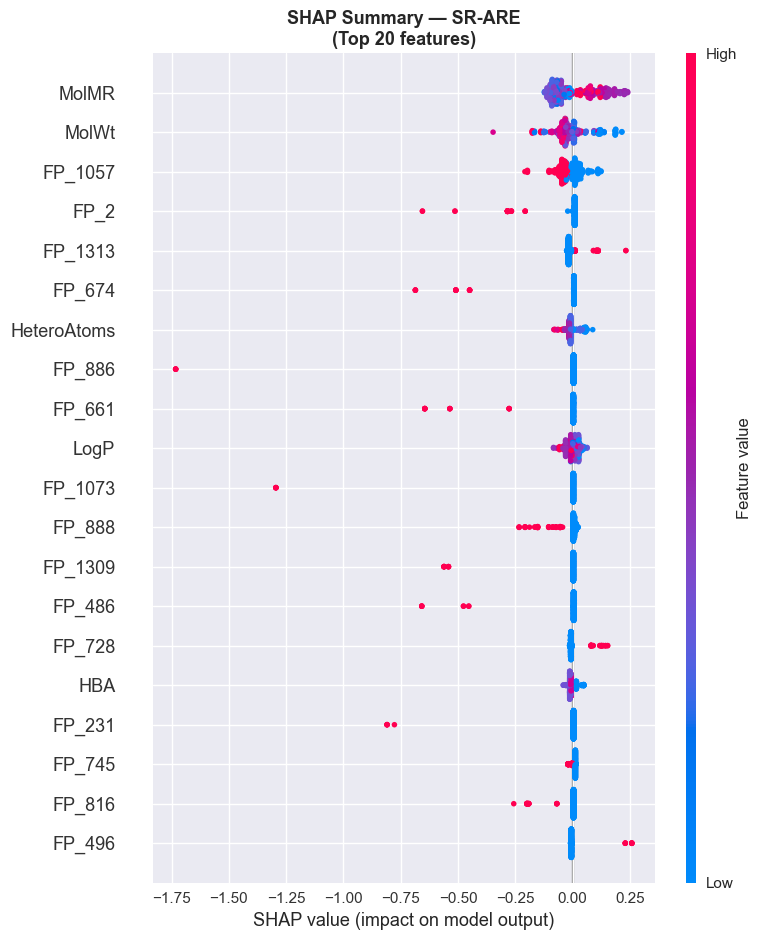

In [20]:
# SHAP Summary Plot (Beeswarm)
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_shap, feature_names=FEATURE_NAMES,
                  max_display=20, show=False)
plt.title(f'SHAP Summary — {primary_target}\n(Top 20 features)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

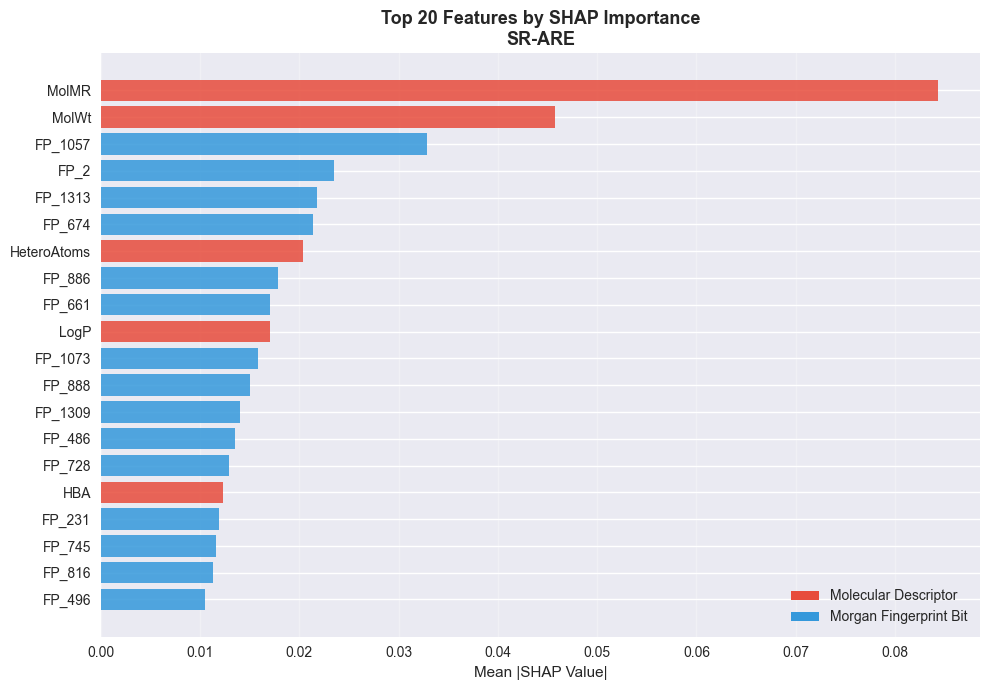


Top 10 Most Important Molecular Properties:
   1. MolMR                     (Descriptor) SHAP=0.08434
   2. MolWt                     (Descriptor) SHAP=0.04577
   3. FP_1057                   (Fingerprint) SHAP=0.03286
   4. FP_2                      (Fingerprint) SHAP=0.02349
   5. FP_1313                   (Fingerprint) SHAP=0.02182
   6. FP_674                    (Fingerprint) SHAP=0.02138
   7. HeteroAtoms               (Descriptor) SHAP=0.02042
   8. FP_886                    (Fingerprint) SHAP=0.01783
   9. FP_661                    (Fingerprint) SHAP=0.01704
  10. LogP                      (Descriptor) SHAP=0.01700


In [21]:
# SHAP Bar Plot — mean absolute impact
mean_shap = np.abs(shap_values).mean(axis=0)
top_idx = np.argsort(mean_shap)[-20:][::-1]
top_features = [FEATURE_NAMES[i] for i in top_idx]
top_shap = mean_shap[top_idx]

# Separate descriptors vs fingerprint bits
colors = ['#e74c3c' if not f.startswith('FP_') else '#3498db' for f in top_features]

plt.figure(figsize=(10, 7))
bars = plt.barh(range(len(top_features)), top_shap, color=colors, alpha=0.85)
plt.yticks(range(len(top_features)), top_features)
plt.xlabel('Mean |SHAP Value|', fontsize=11)
plt.title(f'Top 20 Features by SHAP Importance\n{primary_target}', fontsize=13, fontweight='bold')

# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#e74c3c', label='Molecular Descriptor'),
                   Patch(facecolor='#3498db', label='Morgan Fingerprint Bit')]
plt.legend(handles=legend_elements, loc='lower right')
plt.gca().invert_yaxis()
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('shap_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nTop 10 Most Important Molecular Properties:')
for i, (feat, val) in enumerate(zip(top_features[:10], top_shap[:10])):
    ftype = 'Descriptor' if not feat.startswith('FP_') else 'Fingerprint'
    print(f'  {i+1:2d}. {feat:25s} ({ftype}) SHAP={val:.5f}')

<Figure size 800x500 with 0 Axes>

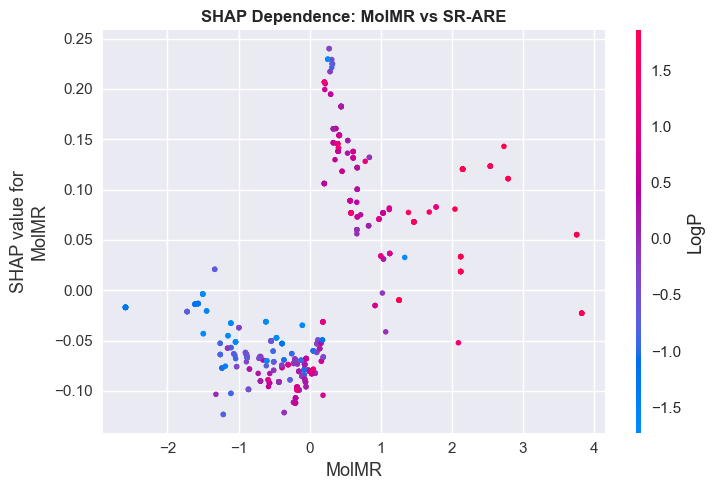

This shows how MolMR values influence toxicity prediction.


In [22]:
# SHAP dependence plot for top descriptor
top_desc_features = [f for f in top_features if not f.startswith('FP_')]
if top_desc_features:
    feat = top_desc_features[0]
    feat_idx = FEATURE_NAMES.index(feat)
    plt.figure(figsize=(8, 5))
    shap.dependence_plot(feat_idx, shap_values, X_shap,
                         feature_names=FEATURE_NAMES, show=False)
    plt.title(f'SHAP Dependence: {feat} vs {primary_target}', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('shap_dependence.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f'This shows how {feat} values influence toxicity prediction.')

## 7. Molecular Property vs Toxicity Analysis

Visualize relationships between key molecular descriptors and toxicity outcomes.

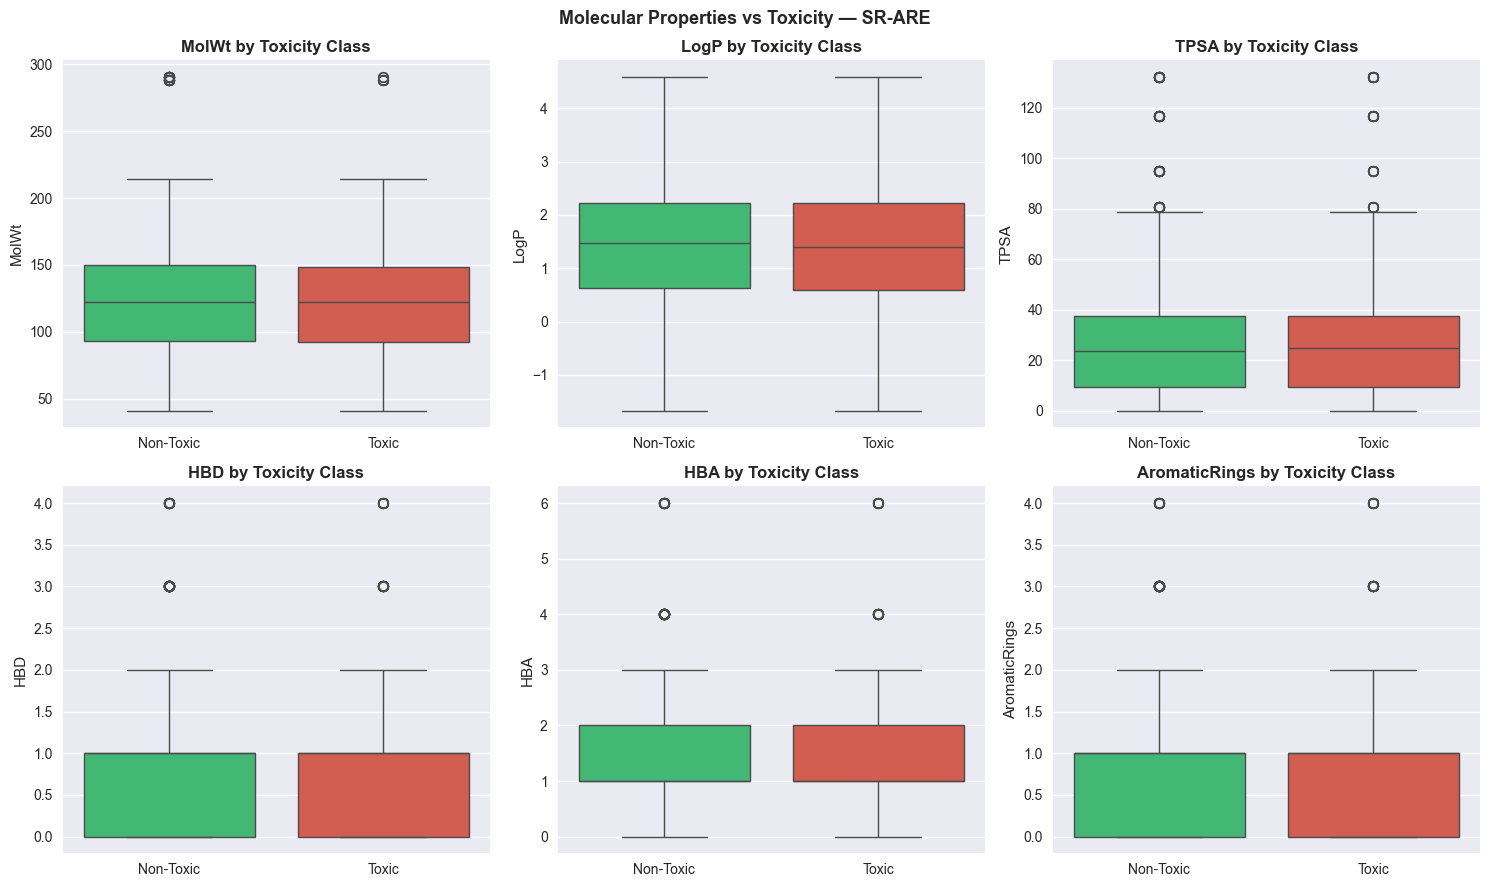

In [23]:
# Box plots: descriptor distributions by toxicity class
target_for_plot = primary_target
mask = df[target_for_plot].notna()
df_plot = df_desc[mask].copy()
df_plot['Toxic'] = df.loc[mask, target_for_plot].map({1.0: 'Toxic', 0.0: 'Non-Toxic'})

plot_descs = ['MolWt', 'LogP', 'TPSA', 'HBD', 'HBA', 'AromaticRings']
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, desc in enumerate(plot_descs):
    sns.boxplot(data=df_plot, x='Toxic', y=desc, ax=axes[i],
                palette={'Toxic': '#e74c3c', 'Non-Toxic': '#2ecc71'})
    axes[i].set_title(f'{desc} by Toxicity Class', fontweight='bold')
    axes[i].set_xlabel('')

plt.suptitle(f'Molecular Properties vs Toxicity — {target_for_plot}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('property_vs_toxicity.png', dpi=150, bbox_inches='tight')
plt.show()

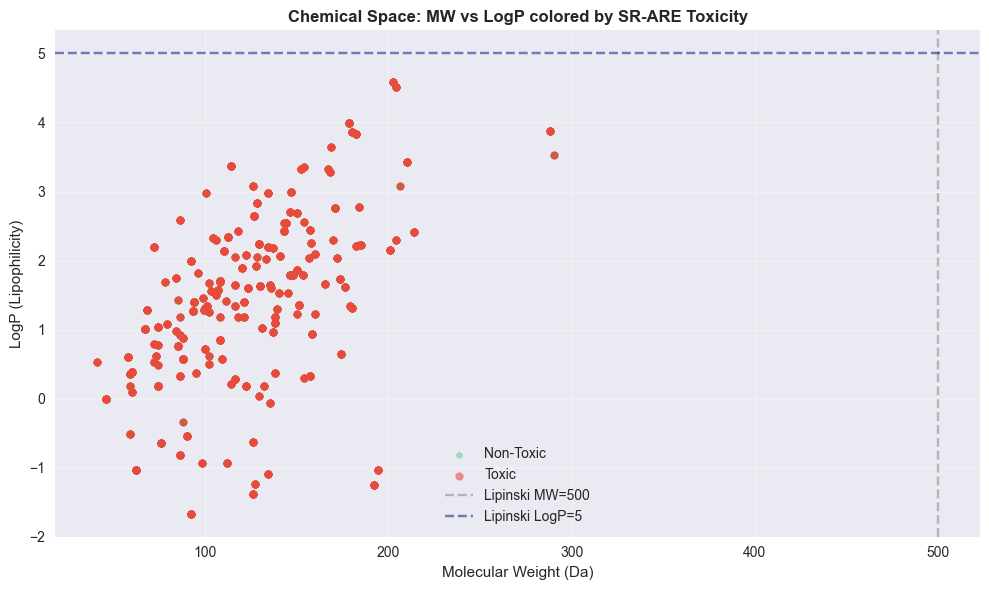

In [24]:
# Scatter: LogP vs MolWt colored by toxicity
plt.figure(figsize=(10, 6))
toxic_mask = df_plot['Toxic'] == 'Toxic'

plt.scatter(df_plot.loc[~toxic_mask, 'MolWt'], df_plot.loc[~toxic_mask, 'LogP'],
            c='#2ecc71', alpha=0.4, s=20, label='Non-Toxic', rasterized=True)
plt.scatter(df_plot.loc[toxic_mask, 'MolWt'], df_plot.loc[toxic_mask, 'LogP'],
            c='#e74c3c', alpha=0.6, s=30, label='Toxic', rasterized=True)

# Lipinski's Rule of 5 boundaries
plt.axvline(500, color='gray', linestyle='--', alpha=0.5, label="Lipinski MW=500")
plt.axhline(5, color='navy', linestyle='--', alpha=0.5, label="Lipinski LogP=5")

plt.xlabel('Molecular Weight (Da)', fontsize=11)
plt.ylabel('LogP (Lipophilicity)', fontsize=11)
plt.title(f'Chemical Space: MW vs LogP colored by {target_for_plot} Toxicity',
          fontsize=12, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('chemical_space.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Single Compound Prediction Function

A simple prediction interface: input a SMILES string, get toxicity probabilities across all trained targets.

In [25]:
def predict_toxicity(smiles_input):
    """
    Predict toxicity for a single compound given its SMILES string.
    Returns probability scores for each trained target using the XGBoost models.
    """
    mol = Chem.MolFromSmiles(smiles_input)
    if mol is None:
        print(f'ERROR: Invalid SMILES string — "{smiles_input}"')
        return None

    # Compute features
    descriptors = np.array(compute_descriptors(smiles_input)).reshape(1, -1)
    fingerprint = np.array(get_fingerprint(smiles_input)).reshape(1, -1)
    X_input = np.hstack([descriptors, fingerprint])

    predictions = {}
    for target in top_targets:
        model = trained_models[target]
        scaler = all_results[target]['results']['XGBoost']['scaler']
        X_sc = scaler.transform(X_input)
        prob = model.predict_proba(X_sc)[0][1]
        predictions[target] = prob

    # Display result
    print(f'\nToxicity Prediction for: {smiles_input}')
    print(f"{'Target':<30} {'Tox Probability':>18} {'Risk Level':>12}")
    print('-' * 62)
    for target, prob in sorted(predictions.items(), key=lambda x: -x[1]):
        risk = 'HIGH' if prob >= 0.7 else 'MEDIUM' if prob >= 0.4 else 'LOW'
        bar = '█' * int(prob * 20)
        print(f'{target:<30} {prob:>15.1%}    {risk:>8}  {bar}')

    return predictions

# Test with Aspirin
aspirin_smiles = 'CC(=O)Oc1ccccc1C(=O)O'
print('--- Aspirin ---')
predict_toxicity(aspirin_smiles)

--- Aspirin ---

Toxicity Prediction for: CC(=O)Oc1ccccc1C(=O)O
Target                            Tox Probability   Risk Level
--------------------------------------------------------------
NR-AhR                                   93.4%        HIGH  ██████████████████
SR-HSE                                   90.2%        HIGH  ██████████████████
SR-MMP                                   85.4%        HIGH  █████████████████
SR-ARE                                   79.8%        HIGH  ███████████████
NR-ER                                    74.8%        HIGH  ██████████████


{'SR-ARE': np.float32(0.79825777),
 'SR-MMP': np.float32(0.85351187),
 'NR-ER': np.float32(0.74780864),
 'NR-AhR': np.float32(0.93403256),
 'SR-HSE': np.float32(0.902025)}

In [26]:
# Test with Caffeine
caffeine_smiles = 'Cn1cnc2c1c(=O)n(C)c(=O)n2C'
print('--- Caffeine ---')
predict_toxicity(caffeine_smiles)

--- Caffeine ---

Toxicity Prediction for: Cn1cnc2c1c(=O)n(C)c(=O)n2C
Target                            Tox Probability   Risk Level
--------------------------------------------------------------
NR-AhR                                   86.2%        HIGH  █████████████████
NR-ER                                    82.6%        HIGH  ████████████████
SR-MMP                                   77.5%        HIGH  ███████████████
SR-ARE                                   72.6%        HIGH  ██████████████
SR-HSE                                   34.6%         LOW  ██████


{'SR-ARE': np.float32(0.7264227),
 'SR-MMP': np.float32(0.774606),
 'NR-ER': np.float32(0.82617),
 'NR-AhR': np.float32(0.8622361),
 'SR-HSE': np.float32(0.34590748)}

In [27]:
# Try your own compound!
# Replace with any valid SMILES string from PubChem, ChEMBL, etc.
custom_smiles = 'C1=CC=CC=C1'  # Benzene — try changing this!
print('--- Custom Compound ---')
predict_toxicity(custom_smiles)

--- Custom Compound ---

Toxicity Prediction for: C1=CC=CC=C1
Target                            Tox Probability   Risk Level
--------------------------------------------------------------
SR-HSE                                   90.2%        HIGH  ██████████████████
NR-ER                                    82.2%        HIGH  ████████████████
SR-ARE                                   78.6%        HIGH  ███████████████
NR-AhR                                   75.6%        HIGH  ███████████████
SR-MMP                                   57.5%      MEDIUM  ███████████


{'SR-ARE': np.float32(0.786411),
 'SR-MMP': np.float32(0.57549244),
 'NR-ER': np.float32(0.8216549),
 'NR-AhR': np.float32(0.75571793),
 'SR-HSE': np.float32(0.9023558)}

## 9. Final Summary

In [28]:
print('='*60)
print('  DRUG TOXICITY PREDICTION — FINAL REPORT')
print('='*60)
print(f'Dataset:          Tox21 ({df.shape[0]:,} compounds, {len(target_cols)} targets)')
print(f'Features:         {len(DESCRIPTOR_NAMES)} descriptors + 2048 Morgan FP bits = {X_combined.shape[1]} total')
print(f'Models trained:   XGBoost, Random Forest, Logistic Regression')
print(f'Imbalance fix:    SMOTE oversampling + class_weight=balanced')
print(f'Evaluation:       ROC-AUC (primary), PR-AUC (secondary)')
print()
print('Model Performance (XGBoost ROC-AUC):')
for target in top_targets:
    auc = all_results[target]['results']['XGBoost']['roc_auc']
    pr  = all_results[target]['results']['XGBoost']['pr_auc']
    print(f'  {target:<30} ROC-AUC: {auc:.4f}  |  PR-AUC: {pr:.4f}')
print()
print('Interpretability: SHAP TreeExplainer — feature importance + dependence plots')
print('Outputs saved:    class_distribution.png, roc_curves.png, auc_heatmap.png,')
print('                  shap_summary.png, shap_importance.png, shap_dependence.png,')
print('                  property_vs_toxicity.png, chemical_space.png')
print('='*60)

  DRUG TOXICITY PREDICTION — FINAL REPORT
Dataset:          Tox21 (7,831 compounds, 12 targets)
Features:         12 descriptors + 2048 Morgan FP bits = 2060 total
Models trained:   XGBoost, Random Forest, Logistic Regression
Imbalance fix:    SMOTE oversampling + class_weight=balanced
Evaluation:       ROC-AUC (primary), PR-AUC (secondary)

Model Performance (XGBoost ROC-AUC):
  SR-ARE                         ROC-AUC: 0.4696  |  PR-AUC: 0.2116
  SR-MMP                         ROC-AUC: 0.5066  |  PR-AUC: 0.1631
  NR-ER                          ROC-AUC: 0.4827  |  PR-AUC: 0.1433
  NR-AhR                         ROC-AUC: 0.5225  |  PR-AUC: 0.1356
  SR-HSE                         ROC-AUC: 0.5048  |  PR-AUC: 0.1121

Interpretability: SHAP TreeExplainer — feature importance + dependence plots
Outputs saved:    class_distribution.png, roc_curves.png, auc_heatmap.png,
                  shap_summary.png, shap_importance.png, shap_dependence.png,
                  property_vs_toxicity.png, chem